In [23]:
import pandas as pd
import numpy as np
import seaborn as sns


In [ ]:
ercot = pd.read_csv("../data/ercot_artifex.csv")

ercot.head()

<Axes: xlabel='hour', ylabel='med_max_spread'>

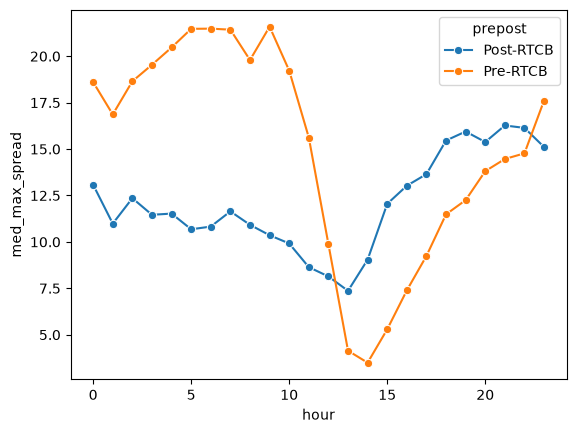

In [29]:
from numpy import median
ercot["time_utc"] = pd.to_datetime(ercot["datetime_utc"], format ="%m/%d/%y %H:%M")

ew = (
ercot.query("type == 'LZ'")
.groupby(["time_utc"], as_index= False)
.agg(max_spread = ("price", lambda x: x.max() - x.min() ))
.assign(hour = lambda x: x["time_utc"].dt.hour, 
        prepost = lambda x: np.where(x["time_utc"] < pd.Timestamp("2025-12-10"), "Pre-RTCB", "Post-RTCB"))
.groupby(["hour", "prepost"], as_index= False)
.agg(med_max_spread = ("max_spread", median))
)

sns.lineplot(data = ew, x = "hour", y = "med_max_spread", hue = "prepost", marker = "o") 
